In [ ]:
#LOGISTIC REGRESSION
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# Create the student dataset
# 30 Student Records with realistic feature interactions
data = {
    "student_id": [f"STU_{i:03d}" for i in range(1, 31)],
    "study_hours": [
        2.0, 3.5, 5.0, 1.5, 6.0, 8.0, 4.5, 2.5, 7.0, 9.0,
        3.0, 4.0, 6.5, 1.0, 5.5, 7.5, 8.5, 2.0, 3.8, 6.0,
        4.2, 5.0, 7.0, 1.5, 8.0, 9.5, 2.5, 3.2, 6.5, 5.2
    ],
    "attendance_pct": [
        60, 72, 85, 50, 88, 95, 76, 65, 90, 98,
        68, 75, 89, 52, 84, 92, 96, 58, 70, 86,
        72, 82, 91, 55, 94, 99, 62, 66, 90, 80
    ],
    "past_score": [
        45, 55, 68, 38, 74, 88, 60, 48, 80, 92,
        50, 62, 76, 35, 70, 85, 90, 42, 53, 72,
        57, 66, 82, 40, 86, 95, 46, 51, 78, 65
    ],
    "practice_tests": [
        1, 2, 4, 0, 5, 7, 3, 1, 6, 8,
        2, 3, 5, 0, 4, 6, 7, 1, 2, 5,
        3, 4, 6, 1, 7, 8, 1, 2, 5, 3
    ],
    "sleep_hours": [
        5.5, 6.0, 7.0, 5.0, 7.5, 8.0, 5.5, 5.5, 7.5, 8.5,
        6.0, 6.5, 7.0, 4.5, 7.0, 8.0, 8.0, 5.0, 6.0, 7.0,
        6.0, 7.0, 7.5, 5.0, 8.0, 8.5, 5.5, 6.0, 7.5, 6.5
    ],
    "passed": [
        0, 0, 1, 0, 1, 1, 0, 0, 1, 1,
        0, 1, 1, 0, 1, 1, 1, 0, 0, 1,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1
    ]
}


df = pd.DataFrame(data)
print("Dataset created successfully!")
display(df.head())

Dataset created successfully!


,student_id,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,passed
0,STU_001,2.0,60,45,1,5.5,0
1,STU_002,3.5,72,55,2,6.0,0
2,STU_003,5.0,85,68,4,7.0,1
3,STU_004,1.5,50,38,0,5.0,0
4,STU_005,6.0,88,74,5,7.5,1


In [3]:
# Check the dataset
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nPass/Fail counts:")
print(df["passed"].value_counts())

Dataset shape: (30, 7)

Data types:
student_id         object
study_hours       float64
attendance_pct      int64
past_score          int64
practice_tests      int64
sleep_hours       float64
passed              int64
dtype: object

Missing values:
student_id        0
study_hours       0
attendance_pct    0
past_score        0
practice_tests    0
sleep_hours       0
passed            0
dtype: int64

Pass/Fail counts:
passed
1    18
0    12
Name: count, dtype: int64


In [4]:
# Separate input features (X) and target (y)
features = ["study_hours", "attendance_pct", "past_score",
            "practice_tests", "sleep_hours"]

X = df[features]
y = df["passed"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (22, 5)
Testing data: (8, 5)


In [5]:
# Scale the features and train the Logistic Regression model
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [6]:
# Predict classes and probabilities
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

results = X_test.copy()
results["Actual_Result"] = y_test
results["Predicted_Result"] = y_pred
results["Pass_Probability"] = y_prob

display(results.round(3))

,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,Actual_Result,Predicted_Result,Pass_Probability
17,2.0,58,42,1,5.0,0,0,0.026
5,8.0,95,88,7,8.0,1,1,0.998
14,5.5,84,70,4,7.0,1,1,0.914
13,1.0,52,35,0,4.5,0,0,0.005
11,4.0,75,62,3,6.5,1,1,0.596
4,6.0,88,74,5,7.5,1,1,0.972
6,4.5,76,60,3,5.5,0,0,0.487
9,9.0,98,92,8,8.5,1,1,0.999


In [7]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Fail", "Pass"], zero_division=0
))

Accuracy: 1.0

Confusion Matrix:
[[3 0]
 [0 5]]

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         3
        Pass       1.00      1.00      1.00         5

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



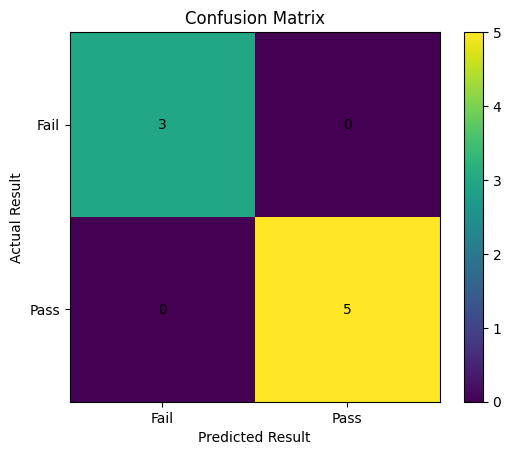

In [8]:
# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

## Explain the concepts in your own words

1. **What is Logistic Regression?**  
   Logistic Regression is a supervised Machine Learning algorithm used to predict categories, such as Pass or Fail.

2. **What is classification?**  
   Classification means predicting which category an input belongs to.

3. **What is probability?**  
   Probability tells us how likely an event is to happen. Its value is between 0 and 1.

4. **What is the sigmoid function?**  
   The sigmoid function converts a model's numerical score into a probability between 0 and 1.

5. **What is a decision threshold?**  
   A threshold converts a probability into a class. With the default threshold of 0.5, a probability of 0.5 or above is classified as 1.

6. **What is the difference between `predict()` and `predict_proba()`?**  
   `predict()` returns the predicted class, while `predict_proba()` returns the probability for each class.

7. **Why do we split the data?**  
   We train the model on training data and evaluate it on testing data to check how it performs on unseen examples.

8. **What is accuracy?**  
   Accuracy is the proportion of correct predictions out of all predictions.

9. **What are common mistakes in Logistic Regression?**  
   Common mistakes include putting the target column in the features, fitting the scaler on test data, evaluating only on training data, and using accuracy alone when classes are imbalanced.

10. **How can we improve the model?**  
    We can clean the data, scale the features correctly, use suitable evaluation metrics, and adjust the decision threshold when needed.